In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [4]:
data = fetch_covtype(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("Cover types:", sorted(y.unique()))

display(X.head())

Dataset shape: (581012, 54)
Target shape: (581012,)
Number of features: 54
Cover types: [1, 2, 3, 4, 5, 6, 7]


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print("Data types:")
print(X.dtypes.value_counts())

print("Missing values:", X.isnull().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Data types:
float64    54
Name: count, dtype: int64
Missing values: 0
Duplicate feature rows: 0

Target distribution:
Cover_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64


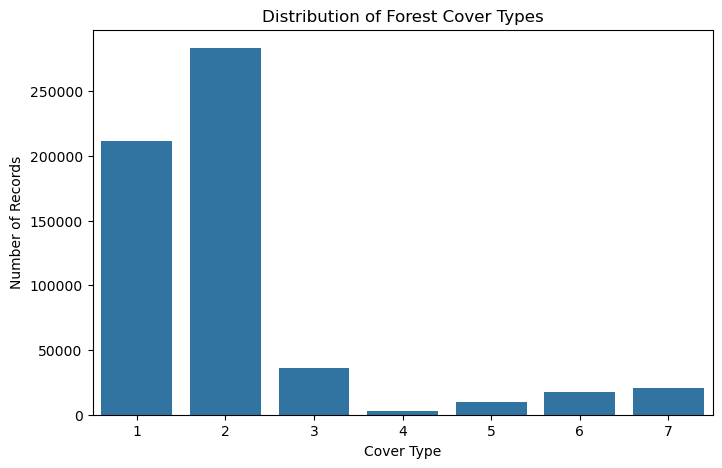

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(x=y)

plt.title("Distribution of Forest Cover Types")
plt.xlabel("Cover Type")
plt.ylabel("Number of Records")
plt.show()

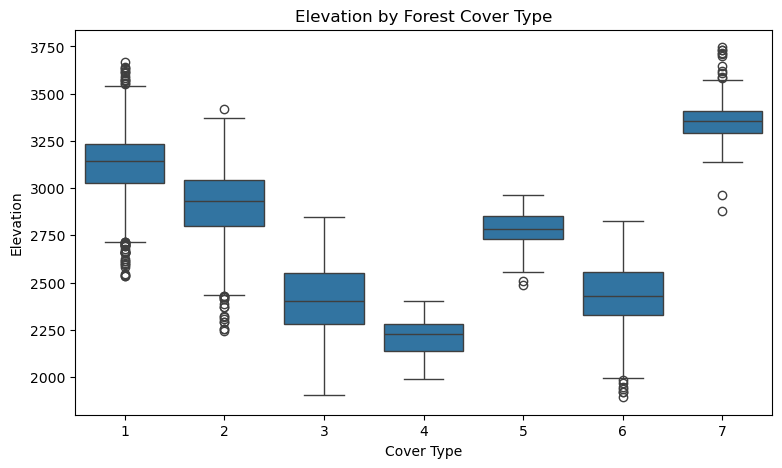

In [7]:
sample = X.sample(
    n=min(10000, len(X)),
    random_state=RANDOM_STATE
)

sample_y = y.loc[sample.index]

plt.figure(figsize=(9, 5))

sns.boxplot(
    x=sample_y,
    y=sample["Elevation"]
)

plt.title("Elevation by Forest Cover Type")
plt.xlabel("Cover Type")
plt.ylabel("Elevation")
plt.show()

In [8]:
X_sample, _, y_sample, _ = train_test_split(
    X,
    y,
    train_size=80000,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    stratify=y_sample,
    random_state=RANDOM_STATE
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 64000
Testing records: 16000


In [9]:
models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            n_jobs=-1
        )
    )
}

In [10]:
results = []
predictions = {}
fitted_models = {}

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    fitted_models[name] = model
    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "F1 Score",
        ascending=False
    ).round(4)
)

Training: Dummy Baseline
Training: Decision Tree
Training: Random Forest
Training: KNN


C:\Users\Soumya\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Soumya\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Soumya\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Soumya\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Soumya\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Crea

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.8973,0.9003,0.7870,0.8301
3,KNN,0.8710,0.7951,0.7708,0.7820
1,Decision Tree,0.8409,0.7905,0.7332,0.7580
0,Dummy Baseline,0.4876,0.0697,0.1429,0.0937


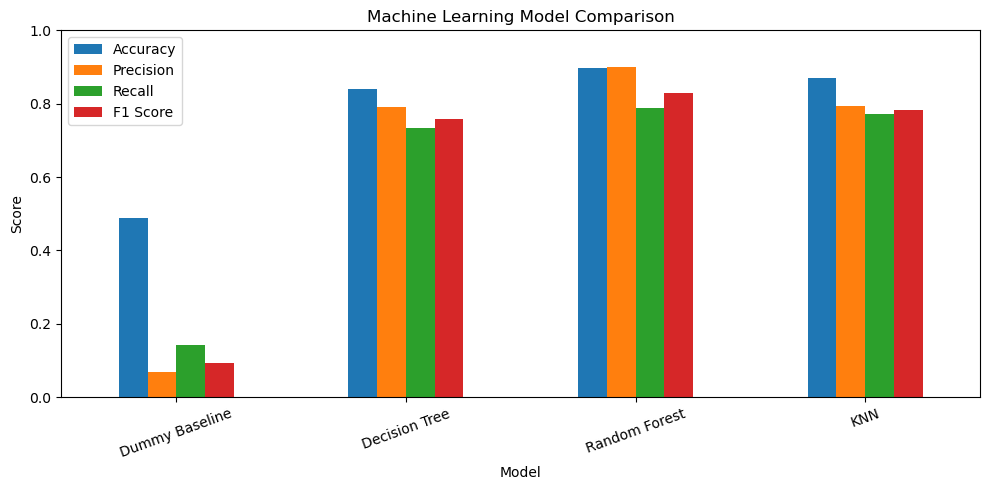

In [11]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [12]:
best_model_name = (
    results_df
    .sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

best_predictions = predictions[best_model_name]

print("Best model:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Best model: Random Forest
              precision    recall  f1-score   support

           1       0.91      0.88      0.89      5834
           2       0.89      0.94      0.91      7802
           3       0.86      0.92      0.89       984
           4       0.92      0.72      0.81        76
           5       0.90      0.46      0.61       261
           6       0.87      0.72      0.79       478
           7       0.95      0.87      0.91       565

    accuracy                           0.90     16000
   macro avg       0.90      0.79      0.83     16000
weighted avg       0.90      0.90      0.90     16000



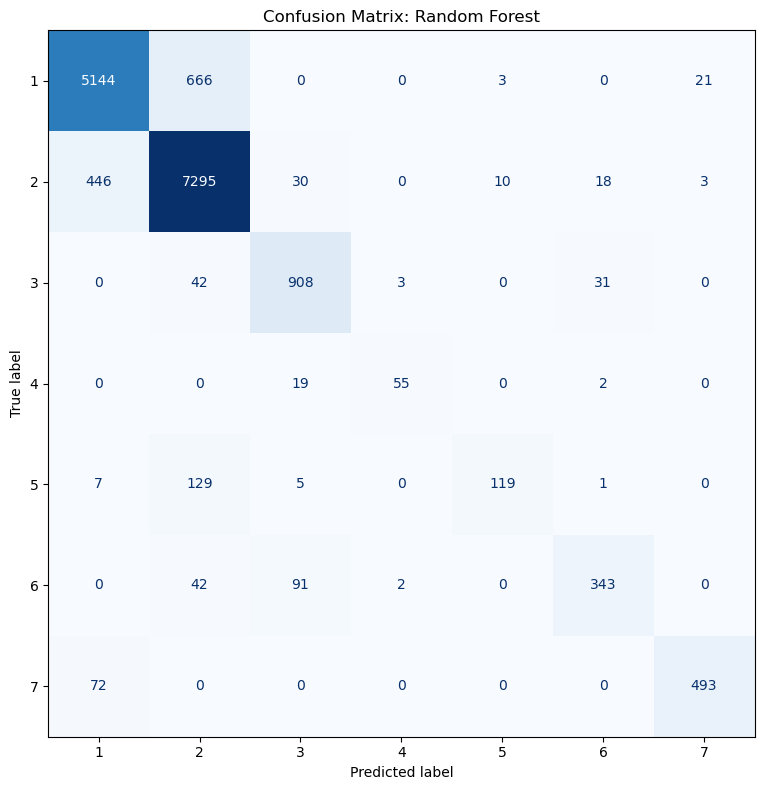

In [13]:
fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title(f"Confusion Matrix: {best_model_name}")

plt.tight_layout()
plt.show()

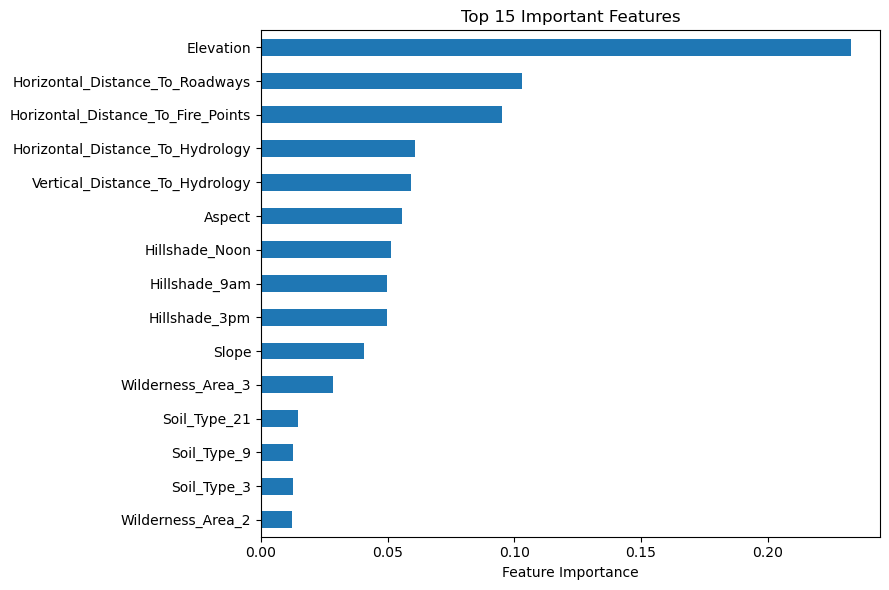

,Importance
Elevation,0.232680
Horizontal_Distance_To_Roadways,0.103139
Horizontal_Distance_To_Fire_Points,0.095273
Horizontal_Distance_To_Hydrology,0.060799
Vertical_Distance_To_Hydrology,0.059051
Aspect,0.055560
Hillshade_Noon,0.051430
Hillshade_9am,0.049846
Hillshade_3pm,0.049764
Slope,0.040802


In [14]:
rf = fitted_models["Random Forest"]

importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(15)

importance.sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

display(importance.to_frame("Importance"))